=== Run 1 / 3 ===
 [Iter 1/300] Loss = 1.111484
 [Iter 51/300] Loss = 0.070851
 [Iter 101/300] Loss = 0.037085
 [Iter 151/300] Loss = 0.030469
 [Iter 201/300] Loss = 0.028218
 [Iter 251/300] Loss = 0.026810
 [Iter 300/300] Loss = 0.025792
=== Run 2 / 3 ===
 [Iter 1/300] Loss = 0.798237
 [Iter 51/300] Loss = 0.085017
 [Iter 101/300] Loss = 0.059066
 [Iter 151/300] Loss = 0.049382
 [Iter 201/300] Loss = 0.043510
 [Iter 251/300] Loss = 0.036453
 [Iter 300/300] Loss = 0.026164
=== Run 3 / 3 ===
 [Iter 1/300] Loss = 0.997712
 [Iter 51/300] Loss = 0.052912
 [Iter 101/300] Loss = 0.028516
 [Iter 151/300] Loss = 0.023250
 [Iter 201/300] Loss = 0.021507
 [Iter 251/300] Loss = 0.020440
 [Iter 300/300] Loss = 0.019702
=== All runs complete ===


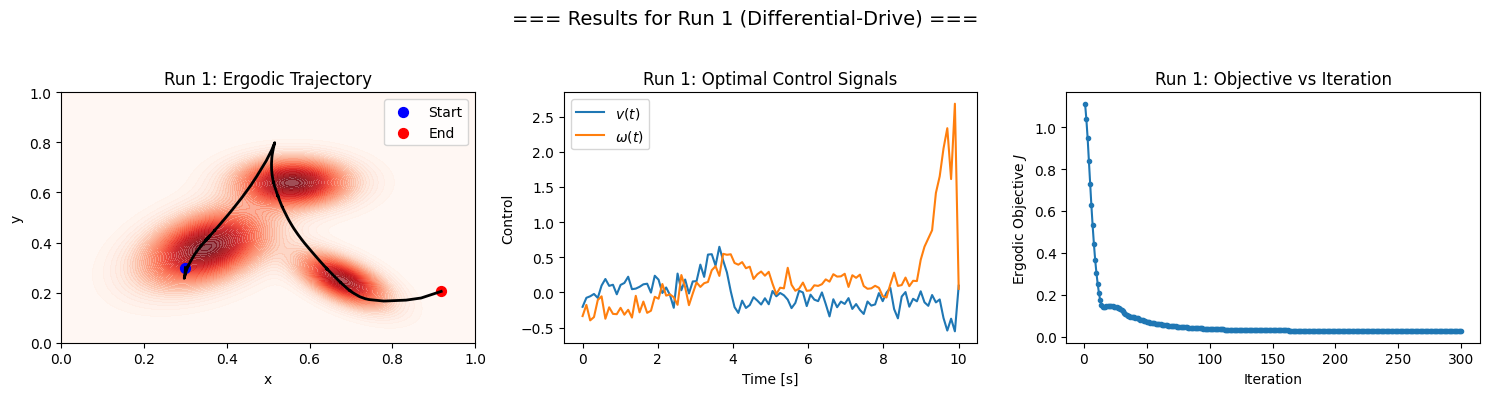

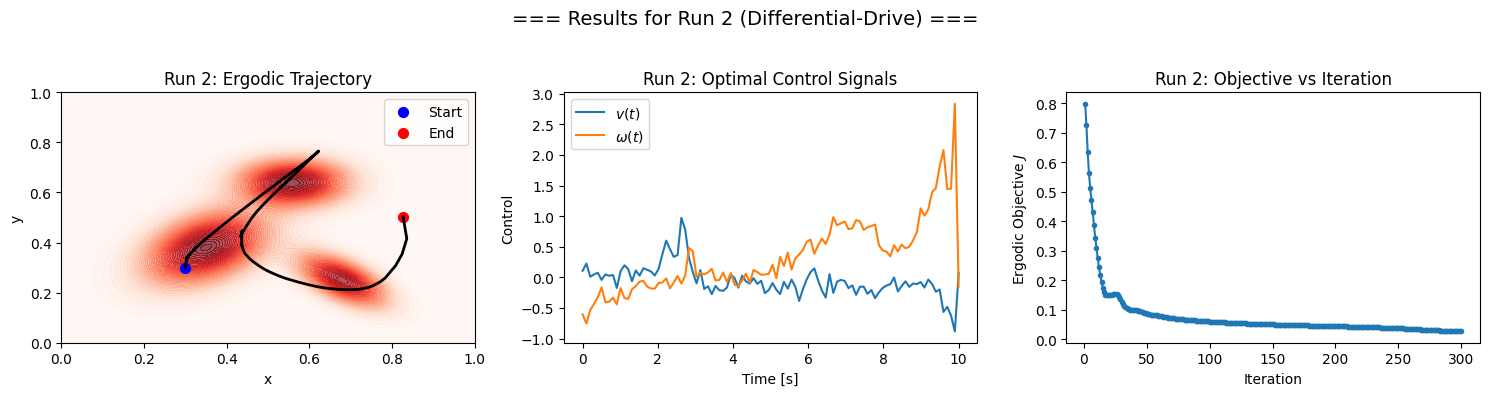

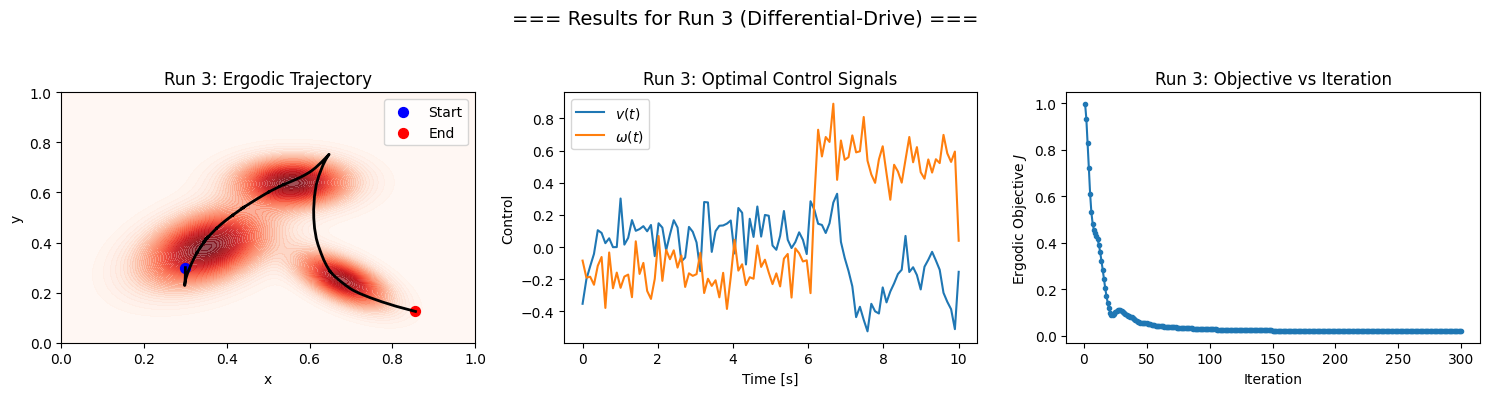

In [ ]:
# If needed, uncomment:
# !pip install torch numpy matplotlib

import numpy as np
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
np.random.seed(0)
torch.manual_seed(0)

# Time setup
T = 10.0
dt = 0.1
N = int(T / dt)
t_grid = np.linspace(0, T, N)

# Target distribution (mixture of 3 Gaussians)
w = np.array([0.5, 0.2, 0.3])
mu = np.array([[0.35, 0.38],
               [0.68, 0.25],
               [0.56, 0.64]])
Sigma = np.array([[[0.01, 0.004], [0.004, 0.01]],
                  [[0.005, -0.003], [-0.003, 0.005]],
                  [[0.008, 0.0], [0.0, 0.004]]])

grid_n = 200
x_vals = np.linspace(0, 1, grid_n)
y_vals = np.linspace(0, 1, grid_n)
dx = 1.0 / (grid_n - 1)
dy = 1.0 / (grid_n - 1)
X, Y = np.meshgrid(x_vals, y_vals)
pos = np.stack([X, Y], axis=-1)

def gaussian_pdf(points, mu_, cov_):
    d = 2
    inv_cov = np.linalg.inv(cov_)
    det_cov = np.linalg.det(cov_)
    norm_const = 1.0 / ((2 * np.pi)**(d/2) * np.sqrt(det_cov))
    diff = points - mu_
    expo = -0.5 * np.sum((diff @ inv_cov) * diff, axis=-1)
    return norm_const * np.exp(expo)

Phi = np.zeros((grid_n, grid_n))
for i in range(3):
    Phi += w[i] * gaussian_pdf(pos, mu[i], Sigma[i])

K = 10
Lambda = np.zeros((K, K))
for i in range(K):
    for j in range(K):
        Lambda[i, j] = 1.0 / (1.0 + (i**2 + j**2))

phi_tgt = np.zeros((K, K))
for i in range(K):
    for j in range(K):
        basis_ij = np.cos(i * np.pi * X) * np.cos(j * np.pi * Y)
        phi_tgt[i, j] = np.sum(basis_ij * Phi) * dx * dy

phi_tgt_torch = torch.tensor(phi_tgt, dtype=torch.double)
Lambda_torch = torch.tensor(Lambda, dtype=torch.double)

# =====================================================
# Run 3 Separate Optimizations
# =====================================================
results = []

for run in range(3):
    print(f"=== Run {run + 1} / 3 ===")

    x0 = torch.tensor([0.3], dtype=torch.double)
    y0 = torch.tensor([0.3], dtype=torch.double)
    theta0 = torch.tensor([np.pi / 2], dtype=torch.double)
    u = torch.nn.Parameter(torch.randn(N, 2, dtype=torch.double) * 0.1)

    optimizer = optim.Adam([u], lr=1e-2)
    n_iters = 300
    obj_hist = []

    for it in range(n_iters):
        optimizer.zero_grad()
        x_list, y_list, th_list = [], [], []
        x_curr, y_curr, th_curr = x0.clone(), y0.clone(), theta0.clone()

        for n in range(N):
            if n > 0:
                v_prev = u[n-1, 0]
                w_prev = u[n-1, 1]
                th_curr = th_curr + w_prev * dt
                x_curr = x_curr + v_prev * torch.cos(th_curr) * dt
                y_curr = y_curr + v_prev * torch.sin(th_curr) * dt
            x_list.append(x_curr)
            y_list.append(y_curr)
            th_list.append(th_curr)

        x_traj = torch.stack(x_list).view(N)
        y_traj = torch.stack(y_list).view(N)

        x_clamped = torch.clamp(x_traj, 0.0, 1.0)
        y_clamped = torch.clamp(y_traj, 0.0, 1.0)

        c_k = torch.zeros(K, K, dtype=torch.double)
        for i in range(K):
            for j in range(K):
                basis = torch.cos(i * np.pi * x_clamped) * torch.cos(j * np.pi * y_clamped)
                c_k[i, j] = torch.mean(basis)

        diff = c_k - phi_tgt_torch
        loss = torch.sum(Lambda_torch * diff**2)

        loss.backward()
        optimizer.step()
        obj_hist.append(loss.item())

        if it % 50 == 0 or it == n_iters - 1:
            print(f" [Iter {it+1}/{n_iters}] Loss = {loss.item():.6f}")

    # Final trajectories
    with torch.no_grad():
        x_list, y_list, th_list = [], [], []
        x_curr, y_curr, th_curr = x0.clone(), y0.clone(), theta0.clone()

        for n in range(N):
            if n > 0:
                v_prev = u[n-1, 0]
                w_prev = u[n-1, 1]
                th_curr = th_curr + w_prev * dt
                x_curr = x_curr + v_prev * torch.cos(th_curr) * dt
                y_curr = y_curr + v_prev * torch.sin(th_curr) * dt
            x_list.append(x_curr)
            y_list.append(y_curr)
            th_list.append(th_curr)

        x_np = torch.stack(x_list).cpu().numpy()
        y_np = torch.stack(y_list).cpu().numpy()
        u_np = u.detach().cpu().numpy()

    results.append({'x': x_np, 'y': y_np, 'u': u_np, 'obj': obj_hist})

print("=== All runs complete ===")

# =====================================================
# Plotting
# =====================================================
for idx, res in enumerate(results):
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.contourf(X, Y, Phi, levels=50, cmap='Reds', alpha=0.7)
    plt.plot(res['x'], res['y'], 'k-', lw=2)
    plt.scatter(res['x'][0], res['y'][0], c='blue', s=50, label='Start')
    plt.scatter(res['x'][-1], res['y'][-1], c='red', s=50, label='End')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'Run {idx + 1}: Ergodic Trajectory')
    plt.legend()
    plt.xlim(0, 1)
    plt.ylim(0, 1)

    plt.subplot(1, 3, 2)
    plt.plot(t_grid, res['u'][:, 0], label='$v(t)$')
    plt.plot(t_grid, res['u'][:, 1], label='$\omega(t)$')
    plt.xlabel('Time [s]')
    plt.ylabel('Control')
    plt.title(f'Run {idx + 1}: Optimal Control Signals')
    plt.legend()

    plt.subplot(1, 3, 3)
    plt.plot(np.arange(1, len(res['obj']) + 1), res['obj'], '-o', markersize=3)
    plt.xlabel('Iteration')
    plt.ylabel(r'Ergodic Objective $J$')
    plt.title(f'Run {idx + 1}: Objective vs Iteration')

    plt.suptitle(f"=== Results for Run {idx + 1} (Differential-Drive) ===", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
